# Analysis of batch run of XOR task
The purpose of this notebook is to plot the training dynamics of relational and self attention across thirty runs.

## Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
results = pd.read_csv('../../data/xor_results.csv')
results.head()

,seed,epoch,self_attention_loss,relational_attention_loss
0,0,0,0.696323,0.709649
1,0,1,0.693384,0.702673
2,0,2,0.689933,0.697412
3,0,3,0.685919,0.694502
4,0,4,0.680553,0.692258


## Make figure

In [3]:
# Group by epoch and compute statistics across all seeds
stats = results.groupby('epoch').agg({
    'self_attention_loss': ['mean', 'std'],
    'relational_attention_loss': ['mean', 'std']
})

epochs = stats.index.values

self_mean = stats['self_attention_loss']['mean']
self_std  = stats['self_attention_loss']['std']

rel_mean = stats['relational_attention_loss']['mean']
rel_std  = stats['relational_attention_loss']['std']

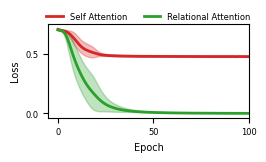

In [18]:
plt.figure(figsize=(2.5, 1.5))

plt.plot(epochs, self_mean, label="Self Attention", linewidth=2, color='tab:red')
plt.fill_between(epochs, self_mean - self_std, self_mean + self_std, alpha=0.3, color='tab:red')

plt.plot(epochs, rel_mean, label="Relational Attention", linewidth=2, color='tab:green')
plt.fill_between(epochs, rel_mean - rel_std, rel_mean + rel_std, alpha=0.3, color='tab:green')

plt.xlabel("Epoch", fontsize=7)
plt.ylabel("Loss", fontsize=7)
plt.xticks(fontsize=6)
plt.yticks(fontsize=6)

plt.xlim(-5, 100)

# small external legend
plt.legend(fontsize=6, loc="upper center", bbox_to_anchor=(0.5, 1.2), ncol=2, frameon=False)

plt.tight_layout(pad=0.1)
plt.savefig('../../results/xor_training_dynamics.svg', bbox_inches="tight", dpi=300)
plt.show()